# ЛР2. Тема 6: ценообразование при известном спросе

**Процесс.** Чайная продаёт линейку напитков и хочет выбрать цены так, чтобы прибыль была максимальной.
Спрос на напиток зависит от его собственной цены и от цен напитков-заменителей.

**Структура ноутбука** повторяет план презентации:

1. Постановка задачи: какие параметры за что отвечают
2. Замена ограничений слагаемыми
3. Метрики решения обычным GD
4. Повышение обусловленности (замена переменных $u = \log p$)
5. Адаптация метода оптимизации (моментум, Нестеров, адаптивный шаг, Ньютон)
6. Робастификация к ошибке в эластичностях
7. Итоговое решение и выводы

Код задачи — `oracles/pricing.py`, новые методы — `methods/heavy_ball.py`, `methods/nesterov.py`, `methods/newton.py`.
Ноутбук должен лежать в папке `lab2/`.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from oracles import tea_shop
from oracles.pricing import TEA_MENU, PricingOracle, ScenarioPricingOracle, tea_shop_scenarios
from methods import GD, AdaptiveStep, HeavyBall, Nesterov, Newton

warnings.filterwarnings("ignore", category=RuntimeWarning)   # переполнения у расходящихся методов ожидаемы
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# оформление графиков: фиксированный порядок цветов, тонкие линии, ненавязчивая сетка
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "axes.prop_cycle": plt.cycler(color=COLORS),
    "legend.frameon": False,
})

RTOL = 1e-8   # общий критерий остановки: f - f* <= RTOL * |f*| (одинаков для любой параметризации)


def iters_to_tol(hist, oracle, rtol=RTOL):
    # первая итерация, на которой f - f* <= rtol * |f*|; None — не достигнуто
    f_star = oracle.info.f_star
    for k, f in enumerate(hist.f):
        if np.isfinite(f) and f - f_star <= rtol * abs(f_star):
            return k
    return None


def price_error(hist, oracle, p_star):
    # ||p_k - p*|| в рублях на каждой итерации
    return np.array([np.linalg.norm(oracle.to_price(x) - p_star) if np.all(np.isfinite(x)) else np.nan
                     for x in hist.x])

## 1. Постановка задачи

Цены $p \in \mathbb{R}^n_{>0}$ для $n$ напитков. Спрос — **изоэластичный с перекрёстными эффектами**:

$$d_i(p) = a_i\, p_i^{-\varepsilon_i} \prod_{j \ne i} p_j^{\gamma_{ij}}, \qquad \log d_i = \log a_i - \varepsilon_i \log p_i + \sum_{j\ne i}\gamma_{ij}\log p_j .$$

Прибыль $\pi(p) = \sum_i (p_i - c_i)\, d_i(p)$. Минимизируем

$$f(p) = -\pi(p) + \frac{\rho}{2}\sum_i (\log p_i - \log p_{0,i})^2 + \frac{\alpha}{2}\|p - p_0\|^2 .$$

| Параметр | Смысл | Как задан |
|---|---|---|
| $p_{0,i}$ | текущая цена напитка, ₽ | меню чайной |
| $c_i$ | себестоимость порции, ₽ | меню |
| $q_{0,i}$ | продажи при текущих ценах, шт./день | меню |
| $\varepsilon_i > 1$ | собственная эластичность: рост своей цены на 1 % снижает спрос на $\varepsilon_i$ % | калибровка (ниже) |
| $\gamma_{ij} \ge 0$ | перекрёстная эластичность: рост цены $j$ на 1 % повышает спрос на $i$ на $\gamma_{ij}$ % (заменители) | 0.08 внутри группы (молочные / фруктовые / прочие), 0.02 между группами |
| $a_i > 0$ | базовый объём спроса | подбирается так, чтобы $d_i(p_0) = q_{0,i}$ |
| $\rho$ | штраф за **относительное** изменение цены | раздел 2 |
| $\alpha$ | штраф за **абсолютное** изменение цены, ₽ | раздел 2 |

**Почему такая модель.** Эластичность — это производная в логарифмах: $\varepsilon = -\partial \log d / \partial \log p$.
Изоэластичная модель предполагает, что она постоянна — стандартное допущение в эконометрике спроса (линейная регрессия $\log d$ на $\log p$).

**Калибровка эластичностей.** Для одного товара оптимальная цена $p^* = c\,\varepsilon/(\varepsilon-1)$ (правило Лернера).
Обратно: текущая цена была бы оптимальной при $\varepsilon = p_0/(p_0-c)$. Мы задали $\varepsilon_i$ немного выше этого значения,
поэтому **без учёта заменителей** все напитки выглядят переоценёнными (колонка «цена по Лернеру» ниже текущей).
Перекрёстные эффекты работают в обратную сторону: повышение цены одного чая частично перетекает в продажи соседних,
поэтому для части напитков (с низкой эластичностью) совместный оптимум окажется **выше** текущей цены.

In [2]:
menu = pd.DataFrame(TEA_MENU, columns=["напиток", "группа", "цена p0, ₽", "себест. c, ₽", "продажи q0, шт/день", "eps"])
menu["eps Лернера p0/(p0-c)"] = menu["цена p0, ₽"] / (menu["цена p0, ₽"] - menu["себест. c, ₽"])
menu["цена по Лернеру c·eps/(eps-1), ₽"] = menu["себест. c, ₽"] * menu["eps"] / (menu["eps"] - 1)
menu

,напиток,группа,"цена p0, ₽","себест. c, ₽","продажи q0, шт/день",eps,eps Лернера p0/(p0-c),"цена по Лернеру c·eps/(eps-1), ₽"
0,Молочный чай с тапиокой,milk,350,90,120,1.41,1.35,309.51
1,Молочный чай таро,milk,380,100,60,1.70,1.36,242.86
2,Матча латте,milk,420,125,45,1.54,1.42,356.48
3,Брауншугар с молоком,milk,390,105,80,1.85,1.37,228.53
4,Фруктовый чай манго,fruit,340,85,90,1.73,1.33,201.44
5,Фруктовый чай маракуйя,fruit,340,85,70,1.87,1.33,182.70
6,Фруктовый чай клубника,fruit,330,80,65,1.91,1.32,167.91
7,Чизфом улун,other,410,115,40,1.46,1.39,365.00
8,Лимонад юдзу,other,300,70,50,1.96,1.30,142.92
9,Холодный жасминовый чай,other,250,50,55,2.00,1.25,100.00


### Проверка оракула

Оракул (`oracles/pricing.py`) считает $f$, градиент и гессиан аналитически. Внутри всё вычисляется в логарифмах цен $u=\log p$
(там спрос — экспонента от линейной функции), а для переменной $p$ производные пересчитываются по цепному правилу.
Проверяем: градиент и гессиан против конечных разностей, калибровку спроса и формулу Лернера.

In [3]:
def fd_check(o, x, h):
    g_fd = np.array([(o.f(x + h * e) - o.f(x - h * e)) / (2 * h) for e in np.eye(o.dim)])
    H_fd = np.column_stack([(o.grad(x + h * e) - o.grad(x - h * e)) / (2 * h) for e in np.eye(o.dim)])
    return (np.abs(o.grad(x) - g_fd).max() / np.abs(g_fd).max(),
            np.abs(o.hess(x) - H_fd).max() / np.abs(H_fd).max())

rng = np.random.default_rng(0)
for param, h in [("price", 1e-4), ("log", 1e-7)]:
    o = tea_shop(10, rho=6000, alpha=0.01, param=param)
    x = o.from_price(o.p0 * rng.uniform(0.8, 1.2, o.dim))
    eg, eh = fd_check(o, x, h)
    print(f"param={param:5s}: отн. ошибка градиента {eg:.1e}, гессиана {eh:.1e}")

o = tea_shop(10)
print("\nкалибровка d(p0) = q0:", np.allclose(o.demand(o.p0), menu["продажи q0, шт/день"]))
print(f"прибыль при текущих ценах: {o.profit(o.p0):,.0f} ₽/день")

# один товар без перекрёстных эффектов и штрафов: должна получиться формула Лернера
single = PricingOracle(a=[1e6], eps=[1.41], gamma=[[0.0]], c=[90], p0=[350])
p_single = single.compute_reference()[0]
print(f"\nодин товар: p* численно = {p_single:.4f} ₽, по формуле c*eps/(eps-1) = {90 * 1.41 / 0.41:.4f} ₽")

param=price: отн. ошибка градиента 2.3e-08, гессиана 3.6e-09
param=log  : отн. ошибка градиента 1.3e-07, гессиана 1.0e-08

калибровка d(p0) = q0: True
прибыль при текущих ценах: 175,425 ₽/день

один товар: p* численно = 309.5122 ₽, по формуле c*eps/(eps-1) = 309.5122 ₽


## 2. Замена ограничений слагаемыми

**Реальные ограничения**, которые есть у чайной:
1. $p_i > 0$ — цена положительна;
2. $|p_i/p_{0,i} - 1| \le \delta$ — нельзя резко менять цену: постоянные клиенты, ценники, позиционирование относительно конкурентов;
3. $|p_i - p_{0,i}| \le \Delta$ — то же в рублях (например, «ценовые точки» 290/350/390 ₽).

В этой ЛР вместо ограничений — **штрафные слагаемые**:
* $\frac{\rho}{2}\sum(\log p_i - \log p_{0,i})^2$ — мягкая версия ограничений 1 и 2: штрафует **относительное** отклонение
  (×2 и ×0.5 одинаково) и уходит в $+\infty$ при $p_i \to 0$ (барьер, держит цену положительной);
* $\frac{\alpha}{2}\|p-p_0\|^2$ — мягкая версия ограничения 3, отклонение в рублях.

### Зачем штрафы нужны: без них задача не имеет решения

Запустим GD при $\rho=\alpha=0$ (маленький шаг, чтобы не было численных эффектов) и посмотрим, куда уходят цены.

In [4]:
o0 = tea_shop(10, rho=0, alpha=0, param="log")
h0 = GD(o0, step=1e-5, max_iter=400, tol=0).run(o0.u0)
P0 = np.exp(np.array(h0.x))
# после ~190 итераций числа переполняются (цены ~1e25 ₽), поэтому показываем до 180
rows = []
for k in [0, 50, 100, 150, 180]:
    p = P0[k]
    rows.append({"итерация": k, "прибыль, ₽/день": o0.profit(p),
                 "цена матчи, ₽": p[2], "цена чизфома, ₽": p[7], "цена тапиоки, ₽": p[0],
                 "продажи матчи, шт": o0.demand(p)[2], "продажи тапиоки, шт": o0.demand(p)[0]})
pd.DataFrame(rows).apply(lambda col: col.map(lambda v: f"{v:,.3g}"))

,итерация,"прибыль, ₽/день","цена матчи, ₽","цена чизфома, ₽","цена тапиоки, ₽","продажи матчи, шт","продажи тапиоки, шт"
0,0,1.75e+05,420,410,350,45,120
1,50,1.99e+05,4.46e+03,1.74e+03,510,1.19,83.2
2,100,2.55e+05,4.92e+05,1.59e+04,459,0.000868,144
3,150,4.8e+05,4.51e+09,1.9e+06,434,7.48e-10,355
4,180,1.41e+06,6.02e+15,1.36e+09,414,3.23e-19,1.38e+03


**Что происходит.** Оптимизатор делает матчу и чизфом бесконечно дорогими. Их продажи падают до нуля,
но по модели перекрёстного спроса $d_i \propto p_j^{\gamma_{ij}}$ спрос на остальные молочные чаи растёт **неограниченно** —
и прибыль вместе с ним. Это артефакт модели: изоэластичный спрос описывает реакцию покупателей только **вблизи текущих цен**.
Штрафы удерживают решение в этой зоне доверия к модели.

### Выбор силы штрафов

Чем больше $\rho$, тем ближе решение к текущим ценам и тем меньше прирост прибыли. Перебираем $\rho$ (при $\alpha=0$).

In [5]:
rows = []
for rho in [3000, 4000, 6000, 10000, 20000, 50000]:
    o = tea_shop(10, rho=rho, alpha=0, param="log")
    ps = o.compute_reference()
    ch = (ps / o.p0 - 1) * 100
    rows.append({"rho": rho, "мин. изменение цены, %": ch.min(), "макс. изменение цены, %": ch.max(),
                 "прирост прибыли, %": (o.profit(ps) / o.profit(o.p0) - 1) * 100})
rho_table = pd.DataFrame(rows)
rho_table

,rho,"мин. изменение цены, %","макс. изменение цены, %","прирост прибыли, %"
0,3000,-46.57,485.00,10.19
1,4000,-44.05,182.88,7.80
2,6000,-39.16,94.89,6.33
3,10000,-30.27,53.11,4.88
4,20000,-17.27,26.86,3.13
5,50000,-7.30,11.23,1.52


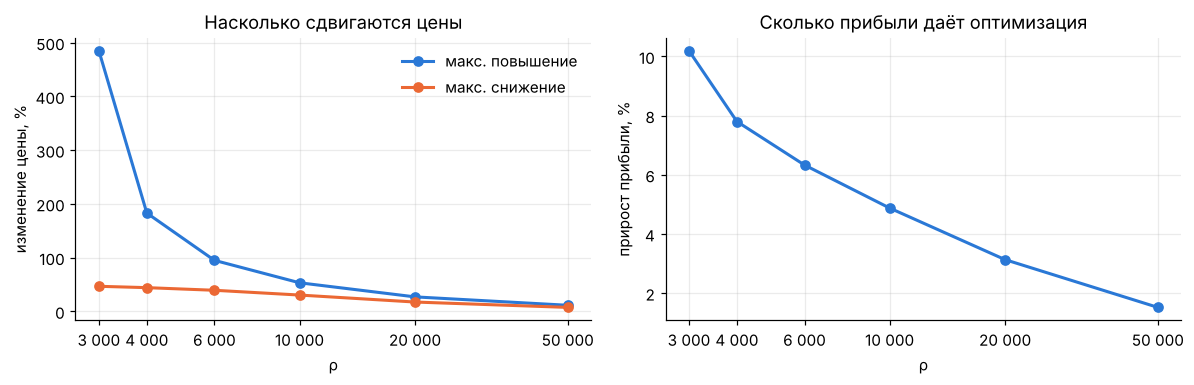

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(rho_table["rho"], rho_table["макс. изменение цены, %"], "-o", color=COLORS[0], label="макс. повышение")
ax[0].plot(rho_table["rho"], -rho_table["мин. изменение цены, %"], "-o", color=COLORS[1], label="макс. снижение")
ax[0].set_xscale("log"); ax[0].set_xlabel("ρ"); ax[0].set_ylabel("изменение цены, %")
ax[0].set_title("Насколько сдвигаются цены"); ax[0].legend()
ax[1].plot(rho_table["rho"], rho_table["прирост прибыли, %"], "-o", color=COLORS[0])
ax[1].set_xscale("log"); ax[1].set_xlabel("ρ"); ax[1].set_ylabel("прирост прибыли, %")
ax[1].set_title("Сколько прибыли даёт оптимизация")
for a in ax:
    a.set_xticks(rho_table["rho"], [f"{v:,.0f}".replace(",", " ") for v in rho_table["rho"]])
    a.minorticks_off()
plt.tight_layout(); plt.show()

**Базовый сценарий: $\rho = 6000$, $\alpha = 0$.** Восемь из десяти цен меняются на 16–39 %, прибыль растёт на 6.3 %.

Ограничение мягкого штрафа видно по матче: даже при $\rho=6000$ модель поднимает её цену почти вдвое, а чтобы удержать
**все** изменения в пределах ±30 %, нужен $\rho = 2\cdot 10^4$ — и тогда прирост прибыли падает вдвое (6.3 % → 3.1 %),
потому что штраф сдерживает и те цены, которые можно было бы двигать свободно.
Штраф одинаково давит на все товары и не умеет сказать «до 30 % можно свободно, дальше нельзя» — это задача
оптимизации с ограничениями (ЛР3). Роль $\alpha$ разберём в разделе 4.

## 3. Метрики решения обычным GD

Решаем в исходной переменной — ценах $p$. Шаг GD $\eta = 1/L$, где $L = \lambda_{\max}(\nabla^2 f(p^*))$ — кривизна в оптимуме.
Эталон $p^*, f^*$ найден методом Ньютона с точностью $10^{-12}$.

Метрики:
* число итераций до $f - f^* \le 10^{-8}|f^*|$ (≈ 0.002 ₽ прибыли) — критерий одинаков для любой параметризации;
* $\|p_k - p^*\|$ в рублях;
* число обусловленности $\kappa = \lambda_{\max}/\lambda_{\min}$ гессиана в оптимуме и в старте.

In [7]:
RHO, ALPHA = 6000, 0.0
o_log = tea_shop(10, rho=RHO, alpha=ALPHA, param="log")
p_star = o_log.compute_reference()
o_price = o_log.with_param("price")

e0 = np.linalg.eigvalsh(o_price.hess(o_price.p0))
print(f"f* = {o_price.info.f_star:,.2f}   прибыль при p*: {o_price.profit(p_star):,.0f} ₽/день "
      f"(+{(o_price.profit(p_star) / o_price.profit(o_price.p0) - 1) * 100:.1f} %)")
print(f"κ в оптимуме: {o_price.info.L / o_price.info.mu:.1f}")
print(f"собств. числа гессиана в старте p0: от {e0.min():.3g} до {e0.max():.3g}  ->  задача НЕВЫПУКЛА в стартовой точке")

t = time.perf_counter()
h_gd_p = GD(o_price, step=1 / o_price.info.L, max_iter=3000, tol=0).run(o_price.p0)
t_gd_p = time.perf_counter() - t
k_gd_p = iters_to_tol(h_gd_p, o_price)
print(f"\nGD по ценам: {k_gd_p} итераций до f-f* <= 1e-8|f*|, время {t_gd_p:.2f} с (3000 итераций)")
print(f"||p - p*|| после {k_gd_p} итераций: {price_error(h_gd_p, o_price, p_star)[k_gd_p]:.2e} ₽")

f* = -182,454.41   прибыль при p*: 186,529 ₽/день (+6.3 %)
κ в оптимуме: 59.6
собств. числа гессиана в старте p0: от -0.0141 до 0.197  ->  задача НЕВЫПУКЛА в стартовой точке

GD по ценам: 332 итераций до f-f* <= 1e-8|f*|, время 0.30 с (3000 итераций)


||p - p*|| после 332 итераций: 6.19e-01 ₽


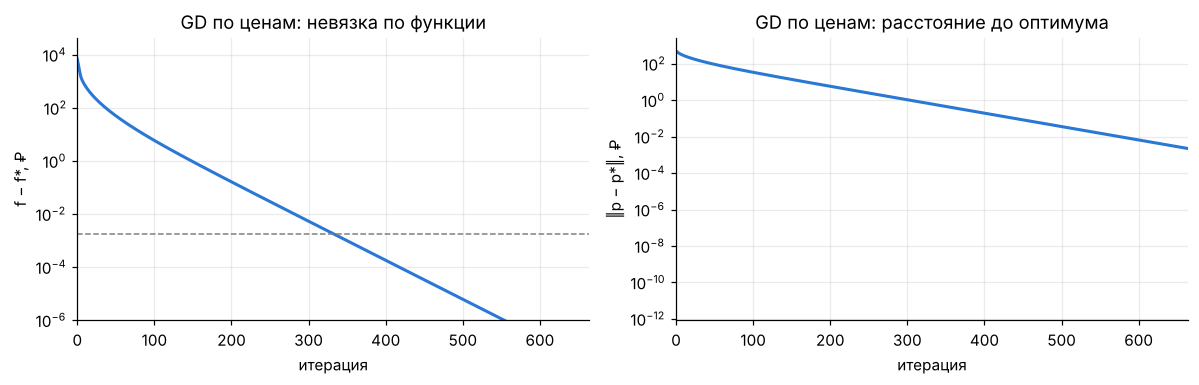

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].semilogy(np.maximum(np.array(h_gd_p.f) - o_price.info.f_star, 1e-12), color=COLORS[0]); ax[0].set_ylim(1e-6, None)
ax[0].axhline(RTOL * abs(o_price.info.f_star), color="gray", ls="--", lw=1)
ax[0].set_xlim(0, 2 * k_gd_p); ax[0].set_xlabel("итерация"); ax[0].set_ylabel("f − f*, ₽")
ax[0].set_title("GD по ценам: невязка по функции")
ax[1].semilogy(price_error(h_gd_p, o_price, p_star), color=COLORS[0])
ax[1].set_xlim(0, 2 * k_gd_p); ax[1].set_xlabel("итерация"); ax[1].set_ylabel("‖p − p*‖, ₽")
ax[1].set_title("GD по ценам: расстояние до оптимума")
plt.tight_layout(); plt.show()

### 2D-пример: тапиока + жасминовый чай

Для визуализации берём два напитка с разным уровнем цен (350 ₽ и 250 ₽) и разной эластичностью.
Траектория GD строится на линиях уровня $f$ в координатах цен — физический смысл сохранён: оси в рублях, цены положительны.

p* = [324.2 121.2] ₽,  κ(p*) в ценах = 7.8,  GD: 63 итераций


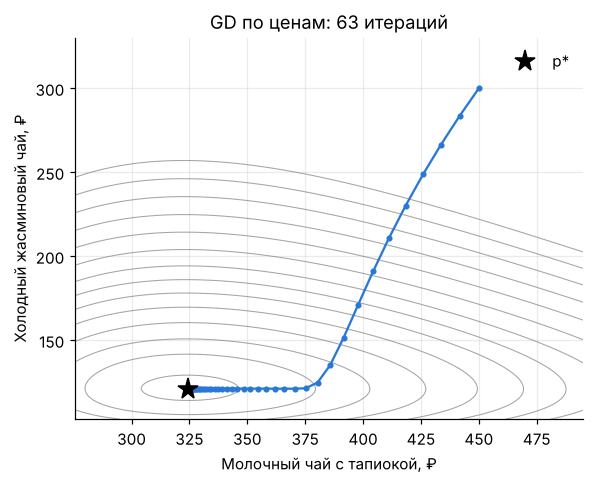

In [9]:
ITEMS = (0, 9)
o2_log = tea_shop(items=ITEMS, rho=RHO, alpha=ALPHA, param="log")
p2_star = o2_log.compute_reference()
o2_price = o2_log.with_param("price")
p2_start = np.array([450.0, 300.0])            # старт подальше от оптимума, чтобы траектория была видна

h2_p = GD(o2_price, step=1 / o2_price.info.L, max_iter=5000, tol=0).run(p2_start)
k2_p = iters_to_tol(h2_p, o2_price)
print(f"p* = {np.round(p2_star, 1)} ₽,  κ(p*) в ценах = {o2_price.info.L / o2_price.info.mu:.1f},  GD: {k2_p} итераций")

def contour_price(ax, o, hist, title, k_show, color):
    P = np.array([o.to_price(x) for x in hist.x[:k_show + 1]])
    lo = np.minimum(P.min(0), p2_star) * 0.85; hi = np.maximum(P.max(0), p2_star) * 1.1
    xs, ys = np.linspace(lo[0], hi[0], 160), np.linspace(lo[1], hi[1], 160)
    Z = np.array([[o2_price.f(np.array([x, y])) for x in xs] for y in ys])
    ax.contour(xs, ys, Z - Z.min(), levels=np.quantile(Z - Z.min(), np.linspace(0.01, 0.6, 14)),
               colors="gray", linewidths=0.7, alpha=0.7)
    ax.plot(P[:, 0], P[:, 1], "-o", ms=3, color=color, lw=1.5)
    ax.plot(*p2_star, "*", ms=14, color="black", label="p*")
    ax.set_xlabel(f"{o.names[0]}, ₽"); ax.set_ylabel(f"{o.names[1]}, ₽"); ax.set_title(title); ax.legend()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
contour_price(ax, o2_price, h2_p, f"GD по ценам: {k2_p} итераций", k2_p, COLORS[0])
plt.tight_layout(); plt.show()

**Вывод по GD.** GD сходится, но медленно: число итераций определяется $\kappa$ — скорость $\approx (1 - 1/\kappa)$ за итерацию.
Траектория сначала быстро идёт по «крутому» направлению, а потом долго ползёт вдоль «пологого» (вытянутые линии уровня).
Кроме того, в стартовой точке гессиан имеет отрицательные собственные числа: гарантии сходимости GD здесь только локальные.

## 4. Повышение обусловленности: замена переменных $u = \log p$

**Идея.** Всё в модели естественно живёт в логарифмах:
* спрос: $\log d = \log a + G u$, $G = -\mathrm{diag}(\varepsilon) + \Gamma$ — линейная функция от $u$;
* штраф $\rho$: $\frac{\rho}{2}\|u - u_0\|^2$ — обычный квадрат, одинаковая кривизна $\rho$ по всем направлениям;
* $p = e^u > 0$ при любом $u$ — ограничение положительности выполняется автоматически, шаг не может «вылететь» в отрицательные цены.

В ценах же кривизна зависит от уровня цены ($\partial^2/\partial p^2 \sim 1/p^2$): напитки за 250 ₽ и за 420 ₽ дают разный масштаб по осям,
а напитки с низкой эластичностью — почти плоские направления. Замена $u=\log p$ — это **диагональное предобуславливание**
матрицей $\mathrm{diag}(p)$: гессиан по $u$ равен $\mathrm{diag}(p)\,\nabla^2_p f\,\mathrm{diag}(p) + \mathrm{diag}(p \odot \nabla_p f)$, второе слагаемое равно нулю в оптимуме.

In [10]:
h_gd_u = GD(o_log, step=1 / o_log.info.L, max_iter=3000, tol=0).run(o_log.u0)
k_gd_u = iters_to_tol(h_gd_u, o_log)

pd.DataFrame({
    "параметризация": ["цены p", "логарифмы u = log p"],
    "κ в оптимуме": [o_price.info.L / o_price.info.mu, o_log.info.L / o_log.info.mu],
    "κ в старте p0": [o_price.condition_number(o_price.p0), o_log.condition_number(o_log.u0)],
    "итераций GD": [k_gd_p, k_gd_u],
    "||p - p*|| на финише, ₽": [price_error(h_gd_p, o_price, p_star)[k_gd_p], price_error(h_gd_u, o_log, p_star)[k_gd_u]],
})

,параметризация,κ в оптимуме,κ в старте p0,итераций GD,"||p - p*|| на финише, ₽"
0,цены p,59.60,inf,332,0.62
1,логарифмы u = log p,4.10,7.84,23,0.59


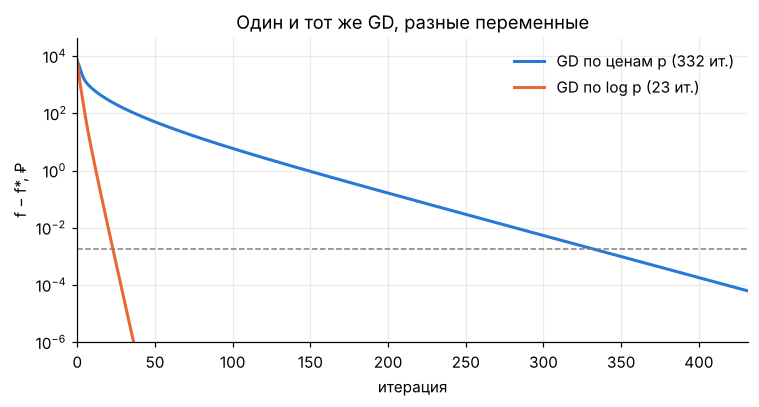

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.semilogy(np.maximum(np.array(h_gd_p.f) - o_price.info.f_star, 1e-12), color=COLORS[0], label=f"GD по ценам p ({k_gd_p} ит.)")
ax.semilogy(np.maximum(np.array(h_gd_u.f) - o_log.info.f_star, 1e-12), color=COLORS[1], label=f"GD по log p ({k_gd_u} ит.)")
ax.set_ylim(1e-6, None)
ax.axhline(RTOL * abs(o_price.info.f_star), color="gray", ls="--", lw=1)
ax.set_xlim(0, 1.3 * k_gd_p); ax.set_xlabel("итерация"); ax.set_ylabel("f − f*, ₽")
ax.set_title("Один и тот же GD, разные переменные"); ax.legend()
plt.tight_layout(); plt.show()

2D: κ в ценах = 7.8, κ в log = 1.1;  GD: 63 vs 5 итераций


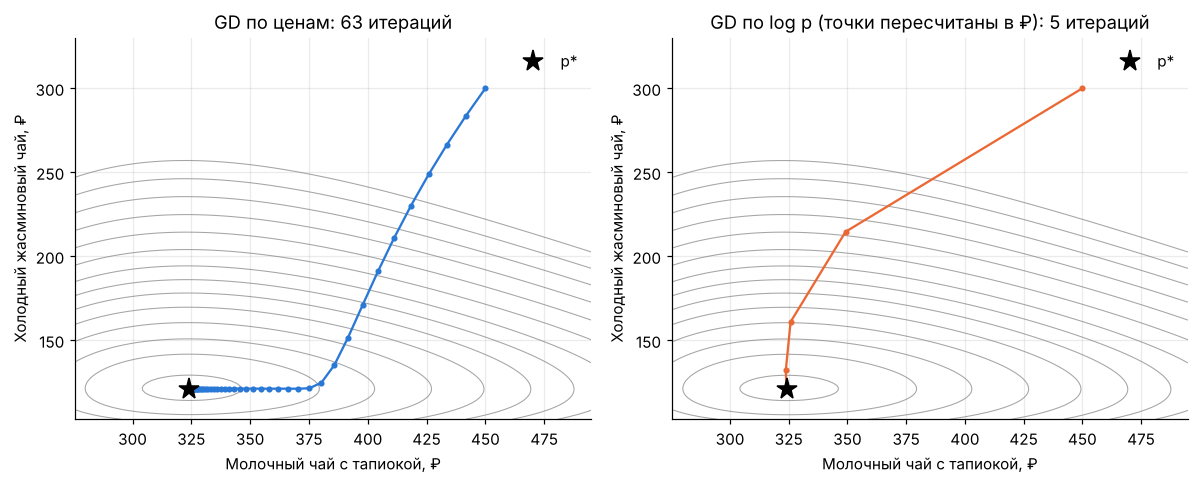

In [12]:
o2_log_run = o2_log
h2_u = GD(o2_log_run, step=1 / o2_log_run.info.L, max_iter=5000, tol=0).run(np.log(p2_start))
k2_u = iters_to_tol(h2_u, o2_log_run)
print(f"2D: κ в ценах = {o2_price.info.L / o2_price.info.mu:.1f}, κ в log = {o2_log.info.L / o2_log.info.mu:.1f};  "
      f"GD: {k2_p} vs {k2_u} итераций")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
contour_price(ax[0], o2_price, h2_p, f"GD по ценам: {k2_p} итераций", k2_p, COLORS[0])
contour_price(ax[1], o2_log_run, h2_u, f"GD по log p (точки пересчитаны в ₽): {k2_u} итераций", k2_u, COLORS[1])
plt.tight_layout(); plt.show()

### Каждому штрафу — свои координаты

Штраф $\alpha$ (в рублях) «круглый» в ценах, а штраф $\rho$ (в процентах) — в логарифмах. Проверим, как они влияют на $\kappa$ в обеих параметризациях.

In [13]:
rows = []
for rho, alpha in [(6000, 0), (6000, 0.01), (6000, 0.05), (6000, 0.5), (20000, 0), (20000, 0.5)]:
    ol = tea_shop(10, rho=rho, alpha=alpha, param="log"); ps = ol.compute_reference()
    op = ol.with_param("price")
    ch = (ps / ol.p0 - 1) * 100
    rows.append({"rho": rho, "alpha": alpha, "изменение цен, %": f"{ch.min():.0f} … +{ch.max():.0f}",
                 "κ в ценах": op.info.L / op.info.mu, "κ в log p": ol.info.L / ol.info.mu})
pd.DataFrame(rows)

,rho,alpha,"изменение цен, %",κ в ценах,κ в log p
0,6000,0.00,-39 … +95,59.60,4.10
1,6000,0.01,-38 … +56,16.46,2.34
2,6000,0.05,-35 … +29,4.52,2.70
3,6000,0.50,-11 … +6,1.29,4.49
4,20000,0.00,-17 … +27,5.40,1.76
5,20000,0.50,-7 … +5,1.21,3.04


**Вывод.** Относительный штраф $\rho$ согласован с переменной $\log p$: переход к логарифмам снижает $\kappa$ в разы, и GD
сходится во столько же раз быстрее. Сильный абсолютный штраф $\alpha$ делает задачу «круглой» уже в ценах — но тогда он же
почти не даёт ценам двигаться (задача становится тривиальной). Для базового сценария ($\alpha=0$) логарифмическая параметризация —
правильный выбор.

## 5. Адаптация метода оптимизации

Сравниваем на 10 напитках в обеих параметризациях:

| Метод | Идея | Параметры |
|---|---|---|
| GD | $x_{k+1} = x_k - \eta \nabla f$ | $\eta = 1/L$ |
| Бэктрекинг (Армихо) | подбор шага по условию достаточного убывания | $\eta_0 = 4/L$ |
| Шаг Поляка | $\eta = (f - f^*)/\|\nabla f\|^2$ | нужен $f^*$ |
| Барзилаи–Борвейн BB1 / BB2 | шаг по секущей: $s^\top s / s^\top y$, $s^\top y / y^\top y$ | — |
| Тяжёлый шар | $x_{k+1} = x_k - \eta\nabla f + \beta(x_k - x_{k-1})$ | $\eta, \beta$ из $L, \mu$ в оптимуме |
| Нестеров | градиент в «заглянувшей вперёд» точке + рестарт при росте $f$ | $\beta = \frac{\sqrt\kappa-1}{\sqrt\kappa+1}$ или $\frac{k-1}{k+2}$ |
| Ньютон | $d = -(\nabla^2 f + \lambda I)^{-1}\nabla f$ + Армихо | $\lambda$ — сдвиг, если гессиан не PD |

In [14]:
def make_methods(o, max_iter=3000):
    L = o.info.L
    return {
        "GD":            GD(o, step=1 / L, max_iter=max_iter, tol=0),
        "бэктрекинг":    AdaptiveStep(o, "backtrack", eta0=4 / L, max_iter=max_iter, tol=0),
        "Поляк":         AdaptiveStep(o, "polyak", eta0=1 / L, max_iter=max_iter, tol=0),
        "BB1":           AdaptiveStep(o, "bb1", eta0=1 / L, max_iter=max_iter, tol=0),
        "BB2":           AdaptiveStep(o, "bb2", eta0=1 / L, max_iter=max_iter, tol=0),
        "тяжёлый шар":   HeavyBall(o, max_iter=max_iter, tol=0),
        "Нестеров":      Nesterov(o, momentum="strongly_convex", max_iter=max_iter, tol=0),
        "Нестеров (k-1)/(k+2)": Nesterov(o, momentum="convex", max_iter=max_iter, tol=0),
        "Ньютон":        Newton(o, max_iter=30, tol=0),
    }

results, histories = [], {}
for label, o in [("цены p", o_price), ("log p", o_log)]:
    x0 = o.from_price(o.p0)
    for name, m in make_methods(o).items():
        t = time.perf_counter(); h = m.run(x0); dt = time.perf_counter() - t
        k = iters_to_tol(h, o)
        histories[(label, name)] = h
        diverged = not np.isfinite(h.f[-1])
        results.append({"параметризация": label, "метод": name,
                        "итераций": k if k is not None else np.nan,
                        "статус": "разошёлся" if diverged else ("сошёлся" if k is not None else "не дошёл"),
                        "время на итерацию, мс": dt / (len(h.f) - 1) * 1e3})
res = pd.DataFrame(results)
res.pivot(index="метод", columns="параметризация", values=["итераций", "статус"])

итераций          статус           
параметризация          log p цены p    log p     цены p
метод                                                   
BB1                     10.00    NaN  сошёлся  разошёлся
BB2                     11.00  46.00  сошёлся    сошёлся
GD                      23.00 332.00  сошёлся    сошёлся
Нестеров                12.00  53.00  сошёлся    сошёлся
Нестеров (k-1)/(k+2)    14.00  45.00  сошёлся    сошёлся
Ньютон                   5.00   6.00  сошёлся    сошёлся
Поляк                   13.00  68.00  сошёлся    сошёлся
бэктрекинг              16.00 223.00  сошёлся    сошёлся
тяжёлый шар              8.00    NaN  сошёлся  разошёлся

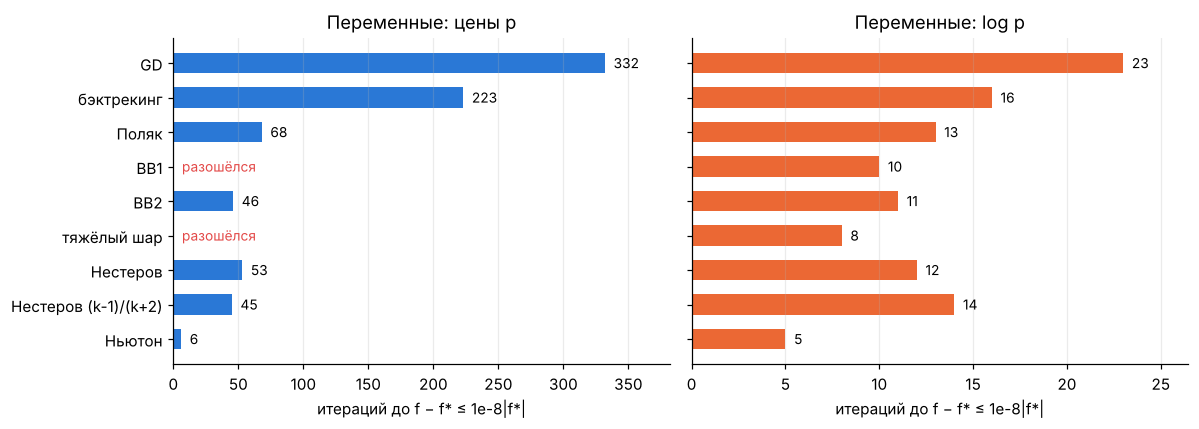

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = [n for n in make_methods(o_log)]
for a, label, col in [(ax[0], "цены p", COLORS[0]), (ax[1], "log p", COLORS[1])]:
    sub = res[res["параметризация"] == label].set_index("метод").loc[order]
    y = np.arange(len(order))
    vals = sub["итераций"].fillna(0).values
    a.barh(y, vals, color=col, height=0.6)
    off = 0.02 * max(vals.max(), 1)
    for yi, v, st in zip(y, vals, sub["статус"]):
        a.text(v + off, yi, f"{int(v)}" if st == "сошёлся" else st, va="center", fontsize=9,
               color="black" if st == "сошёлся" else COLORS[7])
    a.set_yticks(y, order if a is ax[0] else [""] * len(order)); a.invert_yaxis()
    a.set_xlim(0, vals.max() * 1.15); a.set_xlabel("итераций до f − f* ≤ 1e-8|f*|")
    a.set_title(f"Переменные: {label}"); a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### Почему в ценах «ломаются» BB1 и тяжёлый шар

In [16]:
h = histories[("цены p", "BB1")]
X = np.array(h.x)
bad = next(k for k, x in enumerate(X) if np.any(x <= 0) or not np.all(np.isfinite(x)))
print(f"BB1: шаги перед вылетом {np.round(h.step_size[bad - 3:bad + 1], 2)}")
print(f"     на итерации {bad} цены: {np.round(X[bad]).astype(int)}  (отрицательная цена -> f вне области)")

h = histories[("цены p", "тяжёлый шар")]
X = np.array(h.x)
bad = next(k for k, x in enumerate(X) if np.any(x <= 0) or not np.all(np.isfinite(x)))
print(f"\nтяжёлый шар: шаг {HeavyBall(o_price).step:.2f}, beta {HeavyBall(o_price).beta:.2f} (подобраны по кривизне в оптимуме)")
print(f"     за итерацию до вылета ({bad - 1}) макс. цена {X[bad - 1].max():,.0f} ₽, на итерации {bad} мин. цена {X[bad].min():,.0f} ₽")

BB1: шаги перед вылетом [  1.82   2.65  10.58 212.99]
     на итерации 8 цены: [ 363  465 1176  133   83  117  153  761  289 -904]  (отрицательная цена -> f вне области)

тяжёлый шар: шаг 5.55, beta 0.59 (подобраны по кривизне в оптимуме)
     за итерацию до вылета (108) макс. цена 371,636 ₽, на итерации 109 мин. цена -103 ₽


* **BB1** берёт шаг $s^\top s / s^\top y$. Вдали от оптимума функция в ценах почти плоская или невыпуклая ($s^\top y \approx 0$ или $<0$):
  шаг становится огромным и выбрасывает цену в отрицательную область.
* **Тяжёлый шар** с параметрами, рассчитанными по $L,\mu$ в оптимуме, раскачивается: в старте задача невыпукла, импульс уносит
  траекторию к ценам в сотни тысяч рублей, где модель неограничена, а затем — в минус.
* В **логарифмах** обе проблемы исчезают: $p=e^u$ всегда положительна, а функция «круглее» и ближе к выпуклой. Поэтому замена переменных
  не только ускоряет GD, но и делает **ускоренные методы безопасными**.
* **Нестеров с рестартом** сходится в обеих параметризациях: рестарт гасит импульс, когда $f$ растёт.
* **Ньютон** сходится за единицы итераций, но каждая итерация — решение системы $n\times n$ ($O(n^3)$) и вычисление гессиана.

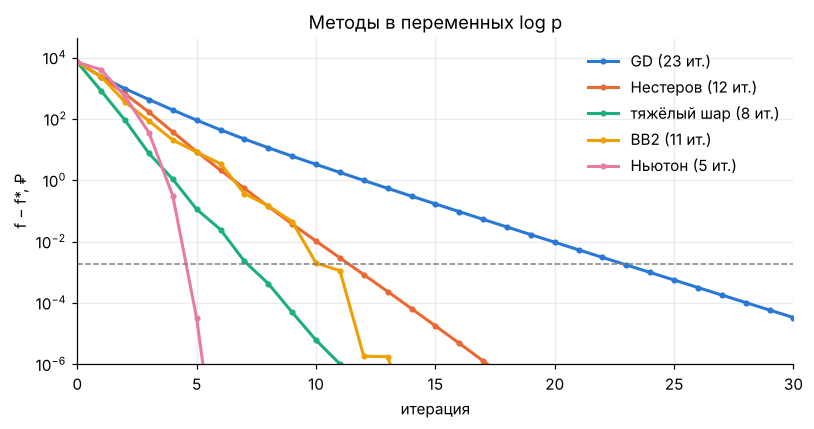

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 4))
show = ["GD", "Нестеров", "тяжёлый шар", "BB2", "Ньютон"]
for i, name in enumerate(show):
    h = histories[("log p", name)]
    k = iters_to_tol(h, o_log)
    ax.semilogy(np.maximum(np.array(h.f) - o_log.info.f_star, 1e-12), color=COLORS[i], label=f"{name} ({k} ит.)", marker="o", ms=3)
ax.axhline(RTOL * abs(o_log.info.f_star), color="gray", ls="--", lw=1)
ax.set_xlim(0, 30); ax.set_ylim(1e-6, None); ax.set_xlabel("итерация"); ax.set_ylabel("f − f*, ₽")
ax.set_title("Методы в переменных log p"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Робастификация к ошибке в эластичностях

Эластичности $\varepsilon_i$ на практике оцениваются по историческим данным с ошибкой. Моделируем ошибку ~15 %:
$\varepsilon_i^{(k)} = \varepsilon_i\, e^{0.15\,\xi_{ik}}$, $\xi \sim N(0,1)$; $a_i$ перекалибровывается, так что при текущих ценах продажи те же —
неопределённо только то, **как** покупатели реагируют на изменение цены.

Сравниваем три решения (обучающие сценарии $K=40$, проверка на 1000 новых сценариях):
* **номинальное** — оптимум при точных $\varepsilon$ (разделы 3–5);
* **SAA** — минимум средней функции $\frac1K\sum_k f_k$ (ожидаемая прибыль);
* **сглаженный худший случай** — $\frac1\tau \log \frac1K\sum_k e^{\tau f_k}$ — гладкая аппроксимация $\max_k f_k$,
  градиент — взвешенное среднее градиентов сценариев (веса softmax).

Все задачи решаются методом Ньютона в переменных $\log p$ (лучший метод из раздела 5).

In [18]:
kw = dict(n=10, rho=RHO, alpha=ALPHA, param="log")
train = tea_shop_scenarios(K=40, sigma=0.15, seed=1, **kw)
test = ScenarioPricingOracle(tea_shop_scenarios(K=1000, sigma=0.15, seed=99, **kw))
profit_now = o_log.profit(o_log.p0)

solutions = {"текущие цены p0": o_log.p0, "номинальное p*": p_star,
             "SAA (среднее)": ScenarioPricingOracle(train, "mean").compute_reference()}
for tau in [1 / 2000, 1 / 500]:
    solutions[f"худший случай, τ=1/{round(1 / tau)}"] = ScenarioPricingOracle(train, "softmax", tau=tau).compute_reference()

rows = []
profit_samples = {}
for name, p in solutions.items():
    pr = test.profits(p); profit_samples[name] = pr
    rows.append({"решение": name, "средняя прибыль": pr.mean(), "5%-квантиль": np.quantile(pr, 0.05),
                 "худший сценарий": pr.min(), "доля сценариев хуже текущих цен, %": (pr < profit_now - 1e-6).mean() * 100})
robust_table = pd.DataFrame(rows).set_index("решение")
robust_table

,средняя прибыль,5%-квантиль,худший сценарий,"доля сценариев хуже текущих цен, %"
решение,,,,
текущие цены p0,"175,425.00","175,425.00","175,425.00",0.00
номинальное p*,"187,337.91","179,976.52","172,179.71",0.80
SAA (среднее),"187,811.75","179,922.35","172,602.01",0.50
"худший случай, τ=1/2000","184,324.86","179,330.34","174,560.76",0.30
"худший случай, τ=1/500","182,613.36","178,363.29","175,114.00",0.10


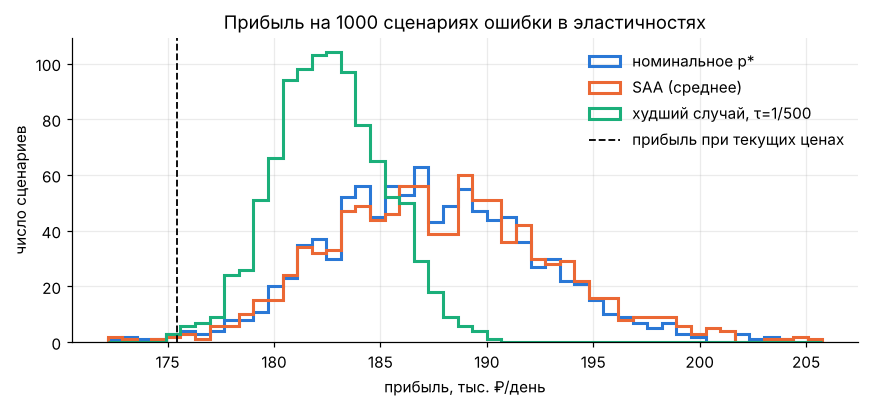

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(min(v.min() for v in profit_samples.values()), max(v.max() for v in profit_samples.values()), 50)
for i, name in enumerate(["номинальное p*", "SAA (среднее)", "худший случай, τ=1/500"]):
    ax.hist(profit_samples[name] / 1e3, bins=bins / 1e3, histtype="step", lw=2, color=COLORS[i], label=name)
ax.axvline(profit_now / 1e3, color="black", ls="--", lw=1.2, label="прибыль при текущих ценах")
ax.set_xlabel("прибыль, тыс. ₽/день"); ax.set_ylabel("число сценариев")
ax.set_title("Прибыль на 1000 сценариях ошибки в эластичностях"); ax.legend()
plt.tight_layout(); plt.show()

**Вывод.** Номинальное решение лучше в среднем, но в части сценариев (когда эластичности оценены с ошибкой) даёт прибыль
**ниже текущей**. Робастная постановка жертвует частью средней прибыли («цена робастности»), зато почти исключает проигрыш
относительно текущих цен. Параметр $\tau$ регулирует компромисс: $\tau\to 0$ — SAA, $\tau\to\infty$ — чистый худший случай.

## 7. Итоговое решение

In [20]:
def k_of(param, name):
    v = res[(res["параметризация"] == param) & (res["метод"] == name)]["итераций"].iloc[0]
    return int(v) if np.isfinite(v) else None

summary = pd.DataFrame([
    {"подход": "GD, цены p (бейзлайн)",          "κ": o_price.info.L / o_price.info.mu, "итераций": k_of("цены p", "GD")},
    {"подход": "Нестеров + рестарт, цены p",     "κ": o_price.info.L / o_price.info.mu, "итераций": k_of("цены p", "Нестеров")},
    {"подход": "GD, log p",                      "κ": o_log.info.L / o_log.info.mu,     "итераций": k_of("log p", "GD")},
    {"подход": "тяжёлый шар, log p",              "κ": o_log.info.L / o_log.info.mu,     "итераций": k_of("log p", "тяжёлый шар")},
    {"подход": "Ньютон, log p",                  "κ": o_log.info.L / o_log.info.mu,     "итераций": k_of("log p", "Ньютон")},
])
summary["ускорение к бейзлайну, раз"] = summary["итераций"].iloc[0] / summary["итераций"]
summary

,подход,κ,итераций,"ускорение к бейзлайну, раз"
0,"GD, цены p (бейзлайн)",59.60,332,1.00
1,"Нестеров + рестарт, цены p",59.60,53,6.26
2,"GD, log p",4.10,23,14.43
3,"тяжёлый шар, log p",4.10,8,41.50
4,"Ньютон, log p",4.10,5,66.40


In [21]:
p_robust = solutions["худший случай, τ=1/500"]
final = pd.DataFrame({
    "напиток": o_log.names,
    "текущая цена, ₽": o_log.p0,
    "оптимальная, ₽": np.round(p_star / 10) * 10,
    "изменение, %": (p_star / o_log.p0 - 1) * 100,
    "робастная, ₽": np.round(p_robust / 10) * 10,
    "изменение робастной, %": (p_robust / o_log.p0 - 1) * 100,
})
print(f"прибыль, ₽/день: текущая {profit_now:,.0f};  при точных eps оптимальная {o_log.profit(p_star):,.0f}")
print(f"в среднем по 1000 сценариям ошибки eps: номинальные цены {robust_table.loc['номинальное p*', 'средняя прибыль']:,.0f}, "
      f"робастные {robust_table.loc['худший случай, τ=1/500', 'средняя прибыль']:,.0f}")
final

прибыль, ₽/день: текущая 175,425;  при точных eps оптимальная 186,529
в среднем по 1000 сценариям ошибки eps: номинальные цены 187,338, робастные 182,613


,напиток,"текущая цена, ₽","оптимальная, ₽","изменение, %","робастная, ₽","изменение робастной, %"
0,Молочный чай с тапиокой,350.00,450.00,27.82,380.00,9.03
1,Молочный чай таро,380.00,440.00,16.07,360.00,-4.96
2,Матча латте,420.00,820.00,94.89,750.00,79.00
3,Брауншугар с молоком,390.00,300.00,-23.49,370.00,-5.48
4,Фруктовый чай манго,340.00,280.00,-18.75,310.00,-8.60
5,Фруктовый чай маракуйя,340.00,260.00,-23.76,310.00,-8.39
6,Фруктовый чай клубника,330.00,240.00,-26.08,280.00,-15.61
7,Чизфом улун,410.00,650.00,58.41,540.00,30.98
8,Лимонад юдзу,300.00,220.00,-26.19,270.00,-11.44
9,Холодный жасминовый чай,250.00,150.00,-39.16,180.00,-28.89


### Выводы

1. **Модель.** Изоэластичный спрос с перекрёстными эффектами калибруется по текущим ценам, себестоимости и продажам; оракул
   проверен конечными разностями (относительная ошибка не больше 1e-7) и формулой Лернера для одного товара (совпадение до 4 знаков).
2. **Ограничения → штрафы.** Без штрафов задача неограничена: оптимизатор делает заменители бесконечно дорогими, и прибыль растёт
   до бесконечности за счёт артефакта модели. Штраф $\rho$ на относительное изменение цены (с барьером при $p\to 0$) возвращает
   задачу в зону доверия модели: при $\rho=6000$ прибыль растёт на 6.3 % (175 425 → 186 529 ₽/день).
   Мягкий штраф не заменяет жёсткое ограничение «±30 %»: для этого нужен $\rho=2\cdot10^4$, и выигрыш падает вдвое — это задача ЛР3.
3. **Бейзлайн GD** в ценах: $\kappa = 59.6$, 332 итерации до точности $10^{-8}|f^*|$; в стартовой точке задача невыпукла.
4. **Обусловленность.** Замена $u = \log p$ — диагональное предобуславливание, согласованное с моделью (эластичности и штраф $\rho$
   живут в логарифмах): $\kappa$ падает с 59.6 до 4.1, GD — с 332 до 23 итераций (×14). Положительность цен выполняется автоматически.
5. **Методы.** В логарифмах ускоренные методы дают ещё ×2–3: тяжёлый шар — 8 итераций, BB1 — 10, Нестеров — 12; Ньютон — 5 (×66 к бейзлайну),
   но каждая его итерация требует гессиана и решения системы $n\times n$. В ценах BB1 и тяжёлый шар **расходятся** (уходят в отрицательные
   цены из-за невыпуклости вдали от оптимума) — замена переменных делает быстрые методы безопасными.
6. **Робастность.** При ошибке оценки эластичностей ~15 % номинальные цены в 0.8 % сценариев дают прибыль ниже текущей (худший случай 172 180 ₽).
   Сглаженная постановка «худшего случая» снижает эту долю до 0.1 % и поднимает худший сценарий до 175 114 ₽, ценой ~4 700 ₽/день средней прибыли.

**Итоговая рекомендация:** решать задачу в переменных $\log p$ методом Ньютона (или тяжёлым шаром для больших $n$),
а для внедрения брать робастные цены — они почти никогда не хуже текущих.